<a href="https://colab.research.google.com/github/hwasun-zip/Who-Needs-the-Ad/blob/main/notebooks/Who_Needs_the_Ad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Who-Needs-the-Ad: 광고가 정말 필요한 사람은 누구인가

광고 노출 예산이 한정되어 있을 때, **누구에게** 광고를 보여줘야 증분 방문과 구매가 가장 커지는가?
"광고를 보면 방문할 사람"이 아니라 "광고를 **봐서** 방문이 **늘어나는** 사람"을 찾는다.

- 데이터: Criteo Uplift Prediction Dataset v2.1 (실제 온라인 광고 무작위 배정 실험, 10% 샘플 1,397,959건)
- 방법: S / T / X-Learner 비교, Qini AUC 평가, 부트스트랩 검증
- 출발점: 같은 데이터로 채권 회수 도메인에 적용한 [Re-Collection](https://github.com/hwasun-zip/Re-Collection)

## 1단계: 환경 준비

In [ ]:
# 1. 라이브러리 설치
!pip install scikit-uplift lightgbm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.3 MB/s eta 0:00:00


In [ ]:
# 2. 불러오기와 출력 설정
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklift.metrics import qini_auc_score, uplift_auc_score, uplift_at_k, qini_curve

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
np.random.seed(42)

In [ ]:
#3. 한글 폰트
!apt-get -qq -y install fonts-nanum > /dev/null 2>&1
import matplotlib.font_manager as fm

fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False
print([f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name])

['NanumGothic']


## 2단계: 데이터 로드와 첫 확인

In [ ]:
# 4. 데이터 불러오기
url = "https://huggingface.co/datasets/criteo/criteo-uplift/resolve/main/criteo-research-uplift-v2.1.csv.gz"

chunks = []
for chunk in pd.read_csv(url, compression='gzip', chunksize=500_000):
    chunks.append(chunk.sample(frac=0.1, random_state=42))
df = pd.concat(chunks, ignore_index=True)

feature_cols = [f'f{i}' for i in range(12)]
print("데이터 크기:", df.shape)

데이터 크기: (1397959, 16)


In [ ]:
# 5. 배정, 노출, 반응 구조 확인
print("[배정 비율]")
print(df['treatment'].value_counts(normalize=True).sort_index())

print("\n[배정 여부별 실제 노출률]")
print(df.groupby('treatment')['exposure'].mean())

print("\n[전체 반응률]")
print(df[['visit', 'conversion']].mean())

[배정 비율]
treatment
0   0.1498
1   0.8502
Name: proportion, dtype: float64

[배정 여부별 실제 노출률]
treatment
0   0.0000
1   0.0361
Name: exposure, dtype: float64

[전체 반응률]
visit        0.0470
conversion   0.0030
dtype: float64


## 3단계: 배정 효과 vs 실제 노출 효과

In [ ]:
def diff_with_ci(y, t):
    """처치군-대조군 반응률 차이와 95% 신뢰구간 (정규근사)"""
    y, t = np.asarray(y), np.asarray(t)
    p1, p0 = y[t == 1].mean(), y[t == 0].mean()
    n1, n0 = (t == 1).sum(), (t == 0).sum()
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    d = p1 - p0
    return p1, p0, d, d - 1.96 * se, d + 1.96 * se

exp_t = df.loc[df['treatment'] == 1, 'exposure'].mean()
exp_c = df.loc[df['treatment'] == 0, 'exposure'].mean()

rows = []
for target in ['visit', 'conversion']:
    p1, p0, d, lo, hi = diff_with_ci(df[target], df['treatment'])
    rows.append([target, p1, p0, d, lo, hi, d / p0, d / (exp_t - exp_c)])

effect_tbl = pd.DataFrame(rows, columns=[
    'target', '처치군_반응률', '대조군_반응률', 'ITT', 'ITT_CI_low', 'ITT_CI_high', 'ITT_상대증가', '노출효과(Wald)'
]).set_index('target')
print(effect_tbl.T)

# * '실제로 노출된 사람들'에 대한 효과
# * '배정만 되고 광고를 안 본 사람은 행동이 안 바뀐다'는 가정
# * 불확실성도 커짐(작은 노출률로 나누기 때문에 ITT의 신뢰구간도 같이 커짐. 대략 25.5 ~ 30.5%p 범위)

target       visit  conversion
처치군_반응률     0.0485      0.0031
대조군_반응률     0.0384      0.0019
ITT         0.0101      0.0013
ITT_CI_low  0.0092      0.0011
ITT_CI_high 0.0110      0.0015
ITT_상대증가    0.2639      0.6761
노출효과(Wald)  0.2803      0.0351


## 4단계: 데이터 분할과 T-Learner 재현

In [ ]:
# 7. 분할
idx_train, idx_test = train_test_split(
    df.index, test_size=0.3, random_state=42, stratify=df['treatment']
)

X_tr, X_te = df.loc[idx_train, feature_cols], df.loc[idx_test, feature_cols]
t_tr, t_te = df.loc[idx_train, 'treatment'].values, df.loc[idx_test, 'treatment'].values
y_tr, y_te = df.loc[idx_train, 'visit'].values, df.loc[idx_test, 'visit'].values
yconv_te = df.loc[idx_test, 'conversion'].values

print("학습:", X_tr.shape, "/ 평가:", X_te.shape)
print("학습 처치군:", (t_tr == 1).sum(), "/ 학습 대조군:", (t_tr == 0).sum())

학습: (978571, 12) / 평가: (419388, 12)
학습 처치군: 831964 / 학습 대조군: 146607


In [ ]:
# 8. T-Learner로 재현 확인
params = dict(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42, verbose=-1)

m_t = lgb.LGBMClassifier(**params).fit(X_tr[t_tr == 1], y_tr[t_tr == 1])
m_c = lgb.LGBMClassifier(**params).fit(X_tr[t_tr == 0], y_tr[t_tr == 0])
uplift_T = m_t.predict_proba(X_te)[:, 1] - m_c.predict_proba(X_te)[:, 1]

print(f"T-Learner Qini AUC: {qini_auc_score(y_te, uplift_T, t_te):.4f}")

T-Learner Qini AUC: 0.0803


## 5단계: S-Learner와 X-Learner

In [ ]:
# 9. S-Learner
m_s = lgb.LGBMClassifier(**params).fit(X_tr.assign(treatment=t_tr), y_tr)
uplift_S = (m_s.predict_proba(X_te.assign(treatment=1))[:, 1]
            - m_s.predict_proba(X_te.assign(treatment=0))[:, 1])

In [ ]:
# 10. X-Learner
# 1단계: 각 유저의 '가상 효과' 만들기
d1 = y_tr[t_tr == 1] - m_c.predict_proba(X_tr[t_tr == 1])[:, 1]   # 처치군: 실제 - (광고 없었다면)
d0 = m_t.predict_proba(X_tr[t_tr == 0])[:, 1] - y_tr[t_tr == 0]   # 대조군: (광고 있었다면) - 실제

# 2단계: 그 효과 자체를 학습
tau1 = lgb.LGBMRegressor(**params).fit(X_tr[t_tr == 1], d1)
tau0 = lgb.LGBMRegressor(**params).fit(X_tr[t_tr == 0], d0)

# 3단계: 두 효과 모델을 가중평균
e = t_tr.mean()   # 무작위 배정이라 배정 확률은 상수 (약 0.85)
uplift_X = e * tau0.predict(X_te) + (1 - e) * tau1.predict(X_te)

In [ ]:
# 11. 예측값 분포 비교
scores = {'S-Learner': uplift_S, 'T-Learner': uplift_T, 'X-Learner': uplift_X}
for name, s in scores.items():
    print(f"{name}: 예측 uplift 범위 {s.min():.4f} ~ {s.max():.4f}, 표준편차 {s.std():.4f}")

S-Learner: 예측 uplift 범위 -0.1232 ~ 0.3581, 표준편차 0.0219
T-Learner: 예측 uplift 범위 -0.3836 ~ 0.6761, 표준편차 0.0319
X-Learner: 예측 uplift 범위 -0.3233 ~ 0.7763, 표준편차 0.0286


## 6단계: 모델 평가

In [ ]:
# 12. 평가 표
eval_rows = []
for name, s in scores.items():
    eval_rows.append([
        name,
        qini_auc_score(y_te, s, t_te),
        uplift_auc_score(y_te, s, t_te),
        uplift_at_k(y_te, s, t_te, strategy='overall', k=0.1),
        uplift_at_k(y_te, s, t_te, strategy='overall', k=0.3),
        qini_auc_score(yconv_te, s, t_te),
    ])
eval_tbl = pd.DataFrame(eval_rows, columns=[
    'model', 'Qini_AUC(visit)', 'Uplift_AUC(visit)', 'Uplift@10%', 'Uplift@30%', 'Qini_AUC(conversion)'
]).set_index('model')
print(eval_tbl)

best_name = eval_tbl['Qini_AUC(visit)'].idxmax()
best_score = scores[best_name]
print(f"\n방문 Qini AUC 기준 최고 모델: {best_name}")

           Qini_AUC(visit)  Uplift_AUC(visit)  Uplift@10%  Uplift@30%  Qini_AUC(conversion)
model                                                                                      
S-Learner           0.0937             0.0366      0.0696      0.0300                0.2246
T-Learner           0.0803             0.0314      0.0614      0.0293                0.1860
X-Learner           0.0791             0.0309      0.0603      0.0291                0.1716

방문 Qini AUC 기준 최고 모델: S-Learner


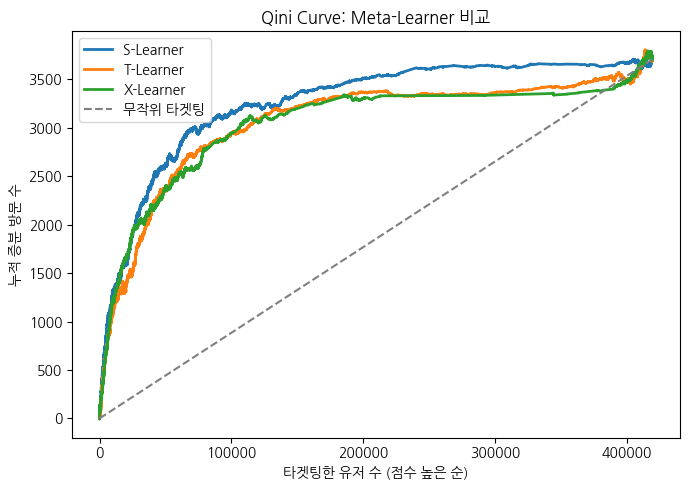

In [ ]:
# 13. Qini Curve 겹쳐 그리기
plt.figure(figsize=(7, 5))
for name, s in scores.items():
    qx, qy = qini_curve(y_te, s, t_te)
    plt.plot(qx, qy, label=name, linewidth=2)
plt.plot([0, qx[-1]], [0, qy[-1]], linestyle='--', color='gray', label='무작위 타겟팅')
plt.xlabel('타겟팅한 유저 수 (점수 높은 순)')
plt.ylabel('누적 증분 방문 수')
plt.title('Qini Curve: Meta-Learner 비교')
plt.legend()
plt.tight_layout()
plt.savefig('qini_comparison.png', dpi=120)
plt.show()

In [ ]:
# 14. 부트스트랩으로 순위 안정성 확인
rng = np.random.default_rng(42)
n = len(y_te)
B = 50
boot = {name: [] for name in scores}

for b in range(B):
    idx = rng.integers(0, n, n)   # 테스트셋에서 복원추출
    for name, s in scores.items():
        boot[name].append(qini_auc_score(y_te[idx], s[idx], t_te[idx]))

boot_df = pd.DataFrame(boot)
print("[Qini AUC 부트스트랩 95% 구간]")
print(boot_df.quantile([0.025, 0.5, 0.975]))
print(f"\nS > T 인 비율: {(boot_df['S-Learner'] > boot_df['T-Learner']).mean():.0%}")
print(f"S > X 인 비율: {(boot_df['S-Learner'] > boot_df['X-Learner']).mean():.0%}")

[Qini AUC 부트스트랩 95% 구간]
        S-Learner  T-Learner  X-Learner
0.0250     0.0748     0.0662     0.0662
0.5000     0.0953     0.0802     0.0784
0.9750     0.1091     0.0994     0.0916

S > T 인 비율: 94%
S > X 인 비율: 94%


## 7단계: 10분위 분석

In [ ]:
# 15. 10분위 함수와 방문 결과
def decile_table(y, t, score, n_bins=10):
    res = pd.DataFrame({'y': y, 't': t, 'score': score})
    res['bin'] = pd.qcut(res['score'].rank(method='first', ascending=False), n_bins, labels=False) + 1
    rates = res.pivot_table(index='bin', columns='t', values='y', aggfunc='mean')
    tbl = pd.DataFrame({
        'n': res.groupby('bin').size(),
        'resp_treat': rates[1],
        'resp_ctrl': rates[0],
    })
    tbl['uplift'] = tbl['resp_treat'] - tbl['resp_ctrl']
    tbl['증분_반응수'] = tbl['uplift'] * tbl['n']
    tbl['누적_증분_비중(%)'] = (tbl['증분_반응수'].cumsum() / tbl['증분_반응수'].sum() * 100).round(1)
    return tbl

dec_visit = decile_table(y_te, t_te, best_score)
print(f"[{best_name} / visit]")
print(dec_visit)

[S-Learner / visit]
         n  resp_treat  resp_ctrl  uplift    증분_반응수  누적_증분_비중(%)
bin                                                             
1    41939      0.2808     0.2112  0.0696 2919.6157      85.8000
2    41939      0.0935     0.0873  0.0062  259.9280      93.4000
3    41939      0.0213     0.0215 -0.0003  -11.6714      93.1000
4    41938      0.0096     0.0081  0.0014   60.8064      94.9000
5    41939      0.0044     0.0045 -0.0001   -3.0791      94.8000
6    41939      0.0021     0.0009  0.0011   46.2502      96.1000
7    41938      0.0013     0.0006  0.0007   29.8173      97.0000
8    41939      0.0019     0.0024 -0.0005  -19.7940      96.4000
9    41939      0.0007     0.0005  0.0002    8.9619      96.7000
10   41939      0.0631     0.0604  0.0027  112.8573     100.0000


In [ ]:
# 16. 같은 점수로 구매 결과
dec_conv = decile_table(yconv_te, t_te, best_score)
print(f"[{best_name} 점수로 줄 세운 conversion 증분]")
print(dec_conv)

[S-Learner 점수로 줄 세운 conversion 증분]
         n  resp_treat  resp_ctrl  uplift   증분_반응수  누적_증분_비중(%)
bin                                                            
1    41939      0.0223     0.0126  0.0098 410.0090      79.6000
2    41939      0.0043     0.0027  0.0016  69.0632      93.0000
3    41939      0.0006     0.0006 -0.0001  -3.0096      92.4000
4    41938      0.0004     0.0000  0.0004  15.3433      95.4000
5    41939      0.0002     0.0000  0.0002   8.2799      97.0000
6    41939      0.0001     0.0000  0.0001   4.7115      97.9000
7    41938      0.0001     0.0002 -0.0001  -4.3111      97.1000
8    41939      0.0001     0.0000  0.0001   4.7161      98.0000
9    41939      0.0000     0.0000  0.0000   1.1728      98.2000
10   41939      0.0028     0.0026  0.0002   9.0447     100.0000


## 8단계: 광고가 역효과를 내는 유저가 정말 있을까

In [ ]:
neg = best_score < 0
p1, p0, d, lo, hi = diff_with_ci(y_te[neg], t_te[neg])
p1_pos, p0_pos, d_pos, lo_pos, hi_pos = diff_with_ci(y_te[~neg], t_te[~neg])

print(f"예측 uplift < 0 유저 비중: {neg.mean():.1%} ({neg.sum():,}명)")
print(f"  예측 uplift 평균: {best_score[neg].mean():.4f}")
print(f"  실제 uplift: {d:.4f}  (95% CI {lo:.4f} ~ {hi:.4f})")
print(f"\n예측 uplift ≥ 0 유저")
print(f"  실제 uplift: {d_pos:.4f}  (95% CI {lo_pos:.4f} ~ {hi_pos:.4f})")

예측 uplift < 0 유저 비중: 6.6% (27,873명)
  예측 uplift 평균: -0.0024
  실제 uplift: 0.0045  (95% CI -0.0048 ~ 0.0138)

예측 uplift ≥ 0 유저
  실제 uplift: 0.0110  (95% CI 0.0093 ~ 0.0126)


## 9단계: 노출 예산 시뮬레이션

In [ ]:
# 18. 예산별 효율 표
budget = pd.DataFrame({
    '노출_대상_비율(%)': np.arange(1, 11) * 10,
    '누적_인원': dec_visit['n'].cumsum().values,
    '누적_증분_방문': dec_visit['증분_반응수'].cumsum().values,
})
total_incr = dec_visit['증분_반응수'].sum()
budget['확보_증분_비중(%)'] = budget['누적_증분_방문'] / total_incr * 100
budget['1000명당_증분_방문'] = budget['누적_증분_방문'] / budget['누적_인원'] * 1000
random_per_1000 = total_incr / dec_visit['n'].sum() * 1000
budget['효율_배수(vs 무작위)'] = budget['1000명당_증분_방문'] / random_per_1000

print(f"무작위 타겟팅 시 1,000명당 증분 방문: {random_per_1000:.2f}\n")
print(budget.round(2).to_string(index=False))

무작위 타겟팅 시 1,000명당 증분 방문: 8.12

 노출_대상_비율(%)  누적_인원  누적_증분_방문  확보_증분_비중(%)  1000명당_증분_방문  효율_배수(vs 무작위)
          10  41939 2919.6200      85.7800       69.6200         8.5800
          20  83878 3179.5400      93.4100       37.9100         4.6700
          30 125817 3167.8700      93.0700       25.1800         3.1000
          40 167755 3228.6800      94.8600       19.2500         2.3700
          50 209694 3225.6000      94.7700       15.3800         1.9000
          60 251633 3271.8500      96.1300       13.0000         1.6000
          70 293571 3301.6700      97.0000       11.2500         1.3900
          80 335510 3281.8700      96.4200        9.7800         1.2100
          90 377449 3290.8400      96.6800        8.7200         1.0700
         100 419388 3403.6900     100.0000        8.1200         1.0000


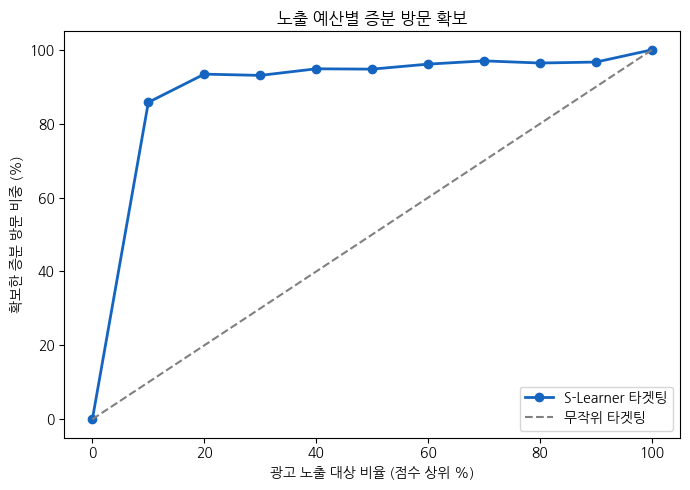

In [ ]:
# 19. 그래프
plt.figure(figsize=(7, 5))
plt.plot([0] + list(budget['노출_대상_비율(%)']), [0] + list(budget['확보_증분_비중(%)']),
         marker='o', linewidth=2, color='#1565C0', label='S-Learner 타겟팅')
plt.plot([0, 100], [0, 100], linestyle='--', color='gray', label='무작위 타겟팅')
plt.xlabel('광고 노출 대상 비율 (점수 상위 %)')
plt.ylabel('확보한 증분 방문 비중 (%)')
plt.title('노출 예산별 증분 방문 확보')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('budget_simulation.png', dpi=120)
plt.show()

## 결과 요약

### 1. 평균 효과: 배정 효과는 실제 노출 효과의 희석된 값이었다
- 캠페인 배정 효과(ITT): 방문 **+1.01%p** (95% CI 0.92 ~ 1.10%p, 상대 +26.4%), 구매 **+0.13%p** (95% CI 0.11 ~ 0.15%p, 상대 +67.6%)
- 처치군 중 실제 노출은 **3.61%**, 대조군은 0%였다. 노출자 기준으로 환산하면(Wald) 방문 확률 **+28.0%p**
- 구매의 상대 증가율이 방문의 약 2.5배로, 광고는 방문보다 구매에 상대적으로 더 큰 영향을 줬다

### 2. 방법론 선택: 이론이 아니라 데이터로 골랐다
| 모델 | Qini AUC (방문) | Qini AUC (구매) |
|---|---|---|
| **S-Learner** | **0.0937** | **0.2246** |
| T-Learner | 0.0803 | 0.1860 |
| X-Learner | 0.0791 | 0.1716 |

- 처치군과 대조군의 불균형(85:15)을 근거로 X-Learner가 유리할 것으로 예상했지만, 가장 단순한 S-Learner가 가장 높았다
- 테스트셋 부트스트랩 50회 중 **94%**에서 S-Learner가 T, X-Learner보다 높아, 순위가 표본에 따라 쉽게 뒤집히지 않음을 확인했다

### 3. 증분 효과는 소수에게 집중되어 있다
- S-Learner 점수 상위 10%가 증분 방문의 **85.8%**, 증분 구매의 79.6%를 차지했다
- 상위 20%까지 넓히면 방문 **93.4%**, 구매 **93.0%**
- 상위 1분위는 방문 21.1% → 28.1%(+33%), 구매 1.26% → 2.23%(+77%)
- 상위 20% 밖의 유저 구간은 증분 효과가 거의 없었다

### 4. '역효과 그룹'은 확인되지 않았다
- 예측 uplift가 음수인 유저 6.6%의 실제 효과는 **+0.45%p** (95% CI -0.48~+1.38%p)로 0과 구분되지 않았다
- 이전 프로젝트(Re-Collection)에서 median split으로 정의한 'Sleeping Dogs'는 근거가 부족했다고 보고, 이 그룹을 '노출 회피'가 아니라 '후순위'로 재정의했다

### 5. 예산 의사결정 기준
- 상위 10%만 노출하면 무작위 타겟팅 대비 **8.6배**의 효율
- 상위 10%를 넘어서면 추가 노출 1,000명당 증분 방문(2분위 6.2건)이 무작위 평균(8.12건)보다 낮다
- 판단 기준: **분위의 '1,000명당 증분 방문 × 방문 가치'가 '1,000명 노출 비용'보다 클 때만 해당 분위까지 노출한다**

### 한계
- 피처가 익명화되어 있어, 증분 효과가 큰 유저가 '어떤 유저인지' 비즈니스 언어로 해석할 수 없다
- 노출 효과(Wald)는 "배정만 되고 광고를 보지 않은 유저는 행동이 바뀌지 않는다"는 가정에 의존한다
- 예산 시뮬레이션의 '1,000명'은 배정 유저 기준이다. 실제 노출 1회당 효율은 분위별 노출률을 반영해야 한다
- 부트스트랩은 평가 데이터의 변동만 반영하며, 모델 재학습에 따른 변동은 반영하지 않는다
- 구매는 매우 드물어 하위 분위의 구매 증분 추정은 불확실성이 크다